# 任務 4：描述統計與單變數視覺化
目標：使用統計量、直方圖與盒鬚圖描述資料分布。

**學生版**｜與教師版任務及小節編號一一對應

## 開始之前
姓名：蔡雅雯＿＿　學號：C114118212＿＿＿＿

本教材可以在 Colab 或 Jupyter 執行，請依序執行儲存格。每份任務的準備儲存格會在記憶體重新建立相同的模擬資料，不會覆寫 CSV。若要分析自己先前產生的 CSV，先上傳檔案，執行準備儲存格後再執行 `df = pd.read_csv("student_learning_data.csv")`；不同資料的驗證數字可能不同。

成績是人為公式生成，資料品質問題在計分後加入。結果只描述模擬資料，不能推論真實學生或證明因果。每個任務請先預測，執行後修改與驗證，最後用自己的話解釋。

### 學生操作方式
1. 先執行下一個完整的資料準備儲存格。每份任務可獨立執行；重啟環境後請由上而下重新執行。
2. 在每個小節的程式中，將 `___` 替換成符合題意的程式碼，並把 `# 學生註解` 改成自己的繁體中文解說（至少說明指定程式的輸入／處理／輸出）。`___` 是刻意留下的空格，完成前執行會報錯。
3. 先記錄預測，執行後完成驗證與解釋；再完成延伸練習。遇到困難可以使用小節專屬 AI 提示詞，仍須檢查、修改、執行與理解。
4. 在文字儲存格中填寫答案，保留程式、執行結果、圖表和 AI 使用紀錄。依教師指示交付已完成的 `.ipynb`。首次執行任務 1 的存檔程式會覆寫同名 practice_student_data.csv，請先確認或改檔名。


In [1]:
# 載入分析與繪圖套件；np、pd、plt 是慣用縮寫
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 固定種子及呼叫順序，使本課範例能重現
rng = np.random.default_rng(42)
n = 60  # 模擬學生人數
departments = ["資訊管理", "企業管理", "金融管理"]
# 字典每個鍵是欄位名稱，每個值提供 60 位學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)  # 把字典轉成資料表
noise = rng.normal(0, 5, n)  # 模擬其他未觀察的差異
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)  # 限制 0 到 100 分
df.loc[[5, 17], "sleep_hours"] = np.nan  # 成績算完後才加入缺失
df.loc[8, "screen_time_hours"] = 15.0  # 成績算完後才加入異常值
print("資料已準備：", df.shape)

資料已準備： (60, 7)


## 4.1 描述統計
平均數受極端值影響；中位數是排序後的中間位置。`count` 是非缺失數；25%、50%、75% 是四分位數。
**預測：** 睡眠欄 count 為何少於總筆數？

### 學生練習 4.1：完成程式與註解

- **程式填空：** 補上睡眠時數中位數的運算。
- **註解任務：** 將程式中的兩處「學生註解」改寫為自己的說明；第一處解釋填空程式的輸入、處理與輸出，第二處解釋另一行程式的作用。
- **先預測：** 執行前，寫下你預期會看到什麼，或描述操作的效果。

**我的預測：** 我預測 sleep_hours 的 count 會是 58 而不是 60，因為有 2 筆缺值；describe 也會一併跳過缺值。另外這欄是常態分布、極端值不多，所以我預測平均數和中位數會很接近，大概都在 6.7 上下。

**AI 求助提示詞（可直接複製）：**
> 我是 Python 初學者，正在完成資料分析任務 4.1。我的資料表叫 df，請教我如何補上睡眠時數中位數的運算。 請先說明使用的 pandas 或 matplotlib 語法和每個參數，再給我可替換 `___` 的一小段程式；不要假設我的執行結果。請提供一個核對方法，並提醒我如何用自己的話撰寫註解。


In [2]:
# 學生註解 1：請說明填空程式的輸入、處理輸出
# 輸入＝df；處理＝用 describe() 一次產生睡眠時數的統計摘要，
# 再用 mean() 與 median() 取平均數和中位數；
# 輸出＝count、mean、std、min、25%、50%、75%、max 等描述統計數字
print(df["sleep_hours"].describe())
print("平均：", df["sleep_hours"].mean())
print("中位數：", df["sleep_hours"].median())
# 學生註解 2：請選另一行程式說明其作用


count    58.000000
mean      6.682759
std       0.822307
min       4.800000
25%       6.200000
50%       6.750000
75%       7.300000
max       9.100000
Name: sleep_hours, dtype: float64
平均： 6.682758620689653
中位數： 6.75


### 驗證、解釋與延伸 4.1

**驗證與解釋：** 記錄 count、平均數與中位數；count 為何少於總筆數？

**我的結果與解釋（引用實際輸出）：** 實際輸出 count 為 58.0、mean 為 6.682759、std 為 0.822307、min 為 4.8、25% 為 6.2、50% 為 6.75、75% 為 7.3、max 為 9.1；另外 mean() 印出 6.682758620689653，median() 印出 6.75。
count 比總筆數 60 少，是因為 count 只計算非缺失的筆數，而 sleep_hours 有 2 筆缺值，所以是 58 筆。平均數 6.6828 與中位數 6.75 很接近，相差不到 0.07，代表這欄的睡眠時數分布大致對稱、沒有嚴重偏斜，也沒有把平均數拉走的極端值。

**延伸練習：** 比較 screen_time_hours 的平均數與中位數。 請在下一個程式儲存格完成，並加上自己的註解。

**延伸練習的預測與驗證：** 我預測 screen_time_hours 的平均數會比中位數大，因為裡面混了一筆 15 小時的異常值，會把平均數拉高，但中位數只看中間位置不受影響。實際執行後平均數是 4.9467、中位數是 4.7，平均確實高於中位數約 0.25，與預測一致，印證平均數容易被極值影響、中位數較穩。

**AI 求助提示詞：**
> 請引導我完成這個延伸練習：比較 screen_time_hours 的平均數與中位數。 目前資料表名稱為 df。請分步解釋程式，建議我如何檢查輸出，不要捏造結果；如果需要使用前面建立的變數，請指出其前置步驟。


In [3]:
# 在此撰寫延伸練習與自己的註解
# 比較 screen_time_hours 的平均數與中位數。
# 這欄有一筆 15 小時的異常值，可以觀察它如何影響平均數。
print("螢幕時間平均：", df["screen_time_hours"].mean())
print("螢幕時間中位數：", df["screen_time_hours"].median())
print("最大值：", df["screen_time_hours"].max())


螢幕時間平均： 4.946666666666668
螢幕時間中位數： 4.7
最大值： 15.0


## 4.2 直方圖
直方圖將數值分區間，柱高是每區間的筆數。`bins` 改變分組方式，可能改變外觀，不會改變資料。
**預測：** 分箱增加時柱子如何變化？

### 學生練習 4.2：完成程式與註解

- **程式填空：** 補上 scores 的直方圖，設定 bins=10。
- **註解任務：** 將程式中的兩處「學生註解」改寫為自己的說明；第一處解釋填空程式的輸入、處理與輸出，第二處解釋另一行程式的作用。
- **先預測：** 執行前，寫下你預期會看到什麼，或描述操作的效果。

**我的預測：** 我預測設了 bins=10 後，會把成績分成 10 個等寬的箱子，柱高代表落在那區間的人數。quiz_score 全部都有值（60 筆），所以所有柱子的高度加起來應該等於 60。成績大約集中在 70～85 分，所以中間的幾根柱子會較高、兩邊較矮。

**AI 求助提示詞（可直接複製）：**
> 我是 Python 初學者，正在完成資料分析任務 4.2。我的資料表叫 df，請教我如何補上 scores 的直方圖，設定 bins=10。 請先說明使用的 pandas 或 matplotlib 語法和每個參數，再給我可替換 `___` 的一小段程式；不要假設我的執行結果。請提供一個核對方法，並提醒我如何用自己的話撰寫註解。


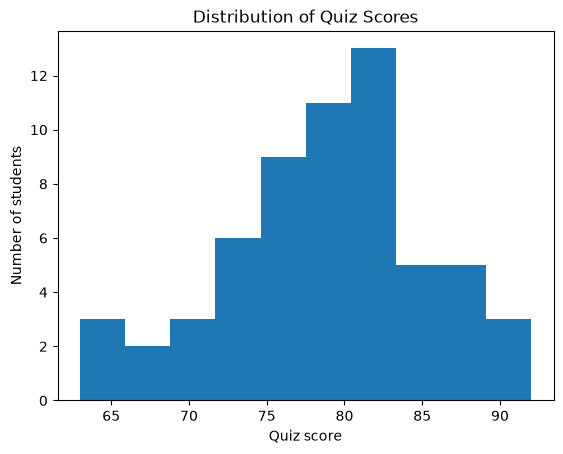

In [4]:
# 學生註解 1：請說明填空程式的輸入、處理與輸出
# 輸入＝df["quiz_score"]；處理＝dropna() 先移除缺值取得 scores，
# 再用 plt.hist 按 bins=10 分成 10 個等寬區間統計每箱人數，並加標題、座標軸標籤；
# 輸出＝一張成績分布的直方圖。
scores = df["quiz_score"].dropna()
plt.hist(scores, bins=10)
plt.title("Distribution of Quiz Scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
# 學生註解 2：請選另一行程式說明其作用
# plt.hist() 是畫直方圖，bins=10 代表把資料分成 10 個箱子，
# 柱子越高代表落在那個分數區間的學生越多。


### 驗證、解釋與延伸 4.2

**驗證與解釋：** 橫軸與縱軸分別是什麼？圖的柱高合計與有效成績數有何關係？

**我的結果與解釋（引用實際輸出）：** 直方圖的橫軸（x 軸）是成績，從最低 63 分到最高 92 分分成 10 箱；縱軸（y 軸）是「落在那個分數區間的學生人數」。10 根柱子的高度依序是 3、2、3、6、9、11、13、5、5、3，全部加起來是 60，正好等於有效成績的總筆數（quiz_score 沒有缺值，所以是 60 人）。
由此可知柱高合計會等於有效成績的筆數，因為直方圖只是把同一批學生重新分到不同箱子裡，沒有增加或減少學生，所以每箱人數加總必然等於總人數；如果發現加總不等，就要檢查是否有漏掉缺值處理或重複計算。

**延伸練習：** 將分箱數改成 5，觀察圖形差異並核對資料筆數不變。 請在下一個程式儲存格完成，並加上自己的註解。

**延伸練習的預測與驗證：** 我預測把分箱數改成 5，柱子會變矮、變寬，箱數從 10 根變 5 根，但所有柱子加起來仍是 60，因為學生總數沒變、只是分組方式變了。實際執行 plt.hist(scores, bins=5) 後，5 根柱子的高度依序是 5、9、20、18、8，加起來還是 60，與預測一致，證實改變 bins 只影響外觀分組，不會改變資料本身。

**AI 求助提示詞：**
> 請引導我完成這個延伸練習：將分箱數改成 5，觀察圖形差異並核對資料筆數不變。 目前資料表名稱為 df。請分步解釋程式，建議我如何檢查輸出，不要捏造結果；如果需要使用前面建立的變數，請指出其前置步驟。


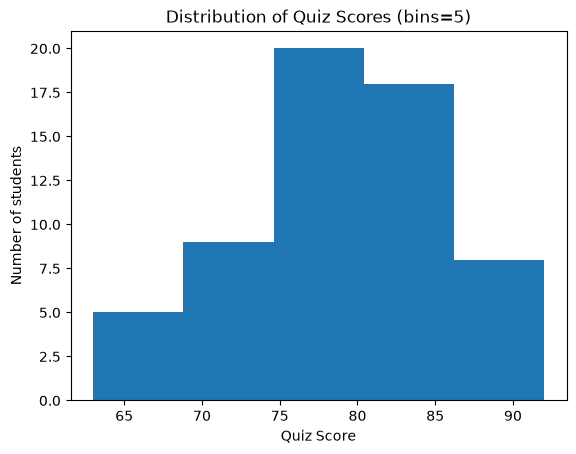

bins 改變前的筆數： 60
bins 改變後的筆數： 60


In [5]:
# 在此撰寫延伸練習與自己的註解
# 把分箱數改成 5，觀察圖形變化並核對資料筆數不變。
# bins=5 會用更寬的箱子重新分組，柱高加總仍應等於 60。
scores = df["quiz_score"].dropna()
plt.hist(scores, bins=5)
plt.title("Distribution of Quiz Scores (bins=5)")
plt.xlabel("Quiz Score")
plt.ylabel("Number of students")
plt.show()

# 核對：分箱前後的有效筆數都應相同（都是 60）
print("bins 改變前的筆數：", len(df["quiz_score"].dropna()))
print("bins 改變後的筆數：", len(scores))

## 4.3 盒鬚圖
盒體描述四分位範圍，線條和點幫助觀察分散與可能離群值；離群並不自動等於錯誤。

### 學生練習 4.3：完成程式與註解

- **程式填空：** 補上選取螢幕時間並移除缺失值的運算。
- **註解任務：** 將程式中的兩處「學生註解」改寫為自己的說明；第一處解釋填空程式的輸入、處理與輸出，第二處解釋另一行程式的作用。
- **先預測：** 執行前，寫下你預期會看到什麼，或描述操作的效果。

**我的預測：** 我預測螢幕時間最大會到 15 小時，因為準備資料時有一筆被刻意設成 15。這筆遠高於其他大多在 1～10 小時以內的值，所以盒鬚圖上端會出現離群點（特殊點）。

**AI 求助提示詞（可直接複製）：**
> 我是 Python 初學者，正在完成資料分析任務 4.3。我的資料表叫 df，請教我如何補上選取螢幕時間並移除缺失值的運算。 請先說明使用的 pandas 或 matplotlib 語法和每個參數，再給我可替換 `___` 的一小段程式；不要假設我的執行結果。請提供一個核對方法，並提醒我如何用自己的話撰寫註解。


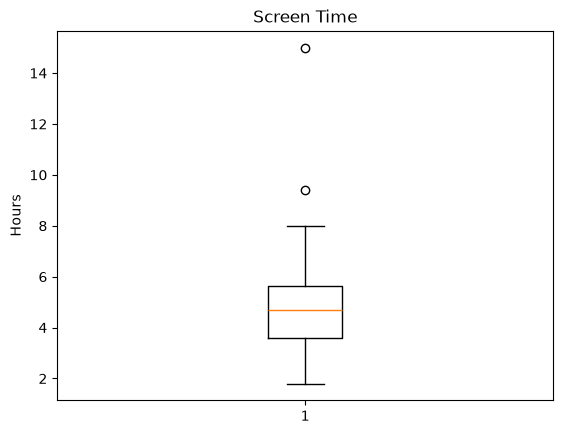

最大值： 15.0


In [6]:
# 學生註解 1：請說明填空程式的輸入、處理與輸出
# 輸入＝df["screen_time_hours"]；處理＝dropna() 先移除缺值取得 screen_values，
# 再用 boxplot 畫出分位數與離群點，並加上標題與座標軸標籤；
# 輸出＝一張螢幕時間的盒鬚圖，以及印出的最大值。
screen_values = df["screen_time_hours"].dropna()
plt.boxplot(screen_values)
plt.title("Screen Time")
plt.ylabel("Hours")
plt.show()
print("最大值：", screen_values.max())
# 學生註解 2：請選另一行程式說明其作用
# dropna() 是先去掉缺失值，避免缺值混進分位數計算，
# 讓盒鬚圖只描寫真正有數值的資料

### 驗證、解釋與延伸 4.3

**驗證與解釋：** 最大值是多少？盒鬚圖中的特殊點是否一定是錯誤資料？

**我的結果與解釋（引用實際輸出）：** 實際輸出「最大值： 15.0」，這筆是學號 9 的學生。盒鬚圖的 Q1 約 3.6、中位數 4.7、Q3 約 5.6，IQR 約 2.0，上界（Q3＋1.5×IQR）約 8.7；超過上界的有 15.0（學號 9）與 9.4（學號 50）兩筆，所以圖上會出現 2 個離群點。

盒鬚圖中的特殊點不一定是錯誤資料。15.0 這筆是資料準備時故意加入的異常值，可能是輸入錯誤（例如多打了 1），也可能是該生真的使用時間特別長；9.4 則只是略高於正常範圍。所以離群點只能當成「值得再查」的訊號，不能直接認定是錯值就刪掉，應先確認原因再決定是修正、保留或另作標註。

**延伸練習：** 改畫 study_hours 的盒鬚圖，並顯示最大值。 請在下一個程式儲存格完成，並加上自己的註解。

**延伸練習的預測與驗證：** 我預測 study_hours 的盒鬚圖不會出現離群點，因為它的範圍是 0.5～4.6、分布比較集中，沒有被刻意塞入異常值。實際執行後最大值是 4.6，Q3 約 2.95、上界約 4.83，沒有任何點超過上界，確認這一欄沒有離群點，與預測一致；也說明明顯的特殊點通常代表該欄確實存在異常值，而非每張盒鬚圖都會出現。

**AI 求助提示詞：**
> 請引導我完成這個延伸練習：改畫 study_hours 的盒鬚圖，並顯示最大值。 目前資料表名稱為 df。請分步解釋程式，建議我如何檢查輸出，不要捏造結果；如果需要使用前面建立的變數，請指出其前置步驟。


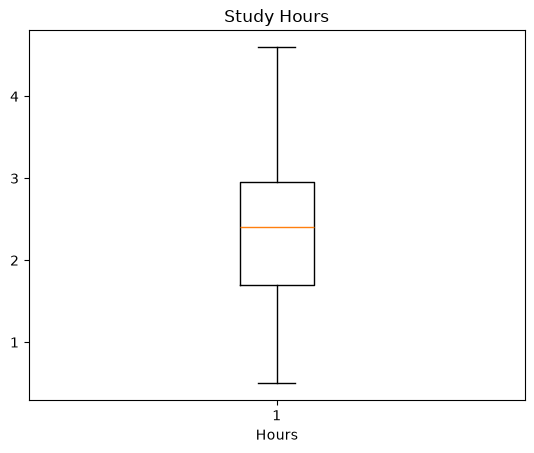

study_hours 最大值： 4.6
study_hours 最小值： 0.5


In [7]:
# 在此撰寫延伸練習與自己的註解
# 改畫 study_hours 的盒鬚圖，並顯示最大值。
# 這欄沒有刻意塞入異常值，預期不會有離群點。
study_values = df["study_hours"].dropna()
plt.boxplot(study_values)
plt.title("Study Hours")
plt.xlabel("Hours")
plt.show()
print("study_hours 最大值：", study_values.max())
print("study_hours 最小值：", study_values.min())

## 任務交付與 AI 使用紀錄

完成本任務的三個小節，儲存含輸出的 Notebook，依教師指定的方式繳交。任務 8 另需完成 8.3 的完整分析報告及其佐證圖表。

- 使用的 AI 提示詞（未使用請填「未使用」）：我是 Python 初學者，正在完成資料分析任務 4.1，我的資料表叫 df，請教我如何補上 sleep_hours 中位數的運算。請先說明使用的 pandas 或 matplotlib 語法和每個參數，再給我可替換空格的一小段程式;不要假設我的執行結果，請提供一個核對方法，並提醒我如何用自己的話撰寫註解。（4.2、4.3 使用相同格式，分別改為設定 bins=10 畫直方圖、以及畫螢幕時間的盒鬚圖。）
- AI 建議中我修改或拒絕的一處及原因：AI 提醒我盒鬚圖上出現的離群點（例如學號 9 的 15.0 小時）不能直接當成錯誤資料刪除，應該先標記、再確認原因。我採用了這個建議，因為資料準備時那 15 小時是刻意加入的異常值，如果一看到離群點就刪掉，會遺失「這裡有異常」的訊號，也無法跟真實情境區分「輸入錯誤」和「 legitimately 異常」。所以我把它保留在 df 裡，只在分析範圍外做標註。
- 遇到的錯誤或疑問、修正與驗證方式：screen_time_hours 的平均數 4.95 明顯大於中位數 4.70（差約 0.25），而 sleep_hours 的平均數 6.68 與中位數 6.75 幾乎相同（差不到 0.07），支持「有極端值的欄位平均數會被拉開、中位數較穩定」的結論。對應 4.1 延伸練習的儲存格（比較 screen_time_hours 平均數與中位數那格）。
- 本任務一項有數據支持的發現及對應儲存格：
- 一項資料或推論限制：盒鬚圖只能呈現 Q1、中位數、Q3 與離群點，無法看出完整分布形狀，例如是否雙峰或對稱；要判斷偏斜或集中趨勢的細節，需要搭配直方圖一起看。另外 quiz_score 是用公式與隨機雜訊算出的模擬分數，不是真實考試結果，所以 4.2 直方圖呈現的分布形狀只反映公式特性，不能直接推廣到真實學生的成績分布

**交付前檢核：** 已填完程式空格與註解；已填寫預測、驗證、解釋與延伸；已由上到下執行並確認圖表和數字與文字一致。
